# Modelo 1 - Regresión: predicción de la nota final (G3)

El Modelo 1 se implementa con programación orientada a objetos y herencia:

- `ModeloBase` (`src/train/utils.py`) es la **clase padre**: prepara los datos, entrena, grafica las pérdidas y guarda el modelo.
- `ModeloRegresion` (`src/train/model1.py`) es la **clase hija**: hereda todo lo anterior y define su propia arquitectura (`crear`) y sus métricas de regresión (`evaluar`).

Cada configuración del modelo es un objeto de la clase `ModeloRegresion`.

# 1.Importación librerías

In [1]:
import sys
sys.path.append('..') #para poder importar la carpeta src desde notebooks/

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src import config
from src.train.model1 import ModeloRegresion

# 2.Importación fuente de datos

In [2]:
#Lectura de los datos ya limpios y procesados en 02_Preprocesamiento
train = pd.read_csv(config.RUTA_PROCESSED / 'train.csv')
test = pd.read_csv(config.RUTA_PROCESSED / 'test.csv')

In [3]:
train.shape, test.shape

((835, 64), (209, 64))

In [4]:
train.head()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,...,higher_no,higher_yes,internet_no,internet_yes,romantic_no,romantic_yes,materia_matematicas,materia_portugues,G3,nivel_riesgo
0,16,3,3,1,2,0,4,3,2,1,...,0,1,1,0,1,0,0,1,13,2
1,15,3,2,1,2,0,4,2,2,1,...,0,1,0,1,1,0,1,0,19,1
2,16,4,3,1,2,0,5,4,2,1,...,0,1,0,1,1,0,0,1,13,2
3,16,2,3,1,2,0,2,3,1,1,...,0,1,0,1,1,0,0,1,14,1
4,17,1,1,3,1,1,5,2,1,1,...,0,1,0,1,0,1,1,0,0,4


# 3.Preparación de variables

## 3.1 Versión A: con notas parciales (G1 y G2)

In [5]:
#Objetos de la Versión A: todas las variables de entrada (se quitan G3, que es la salida, y nivel_riesgo, que se calculó a partir de G3)
modelo_A = ModeloRegresion(version='A', usar_dropout=False)
modelo_A_drop = ModeloRegresion(version='A', usar_dropout=True)
modelo_A.columnas_quitar

['G3', 'nivel_riesgo']

In [6]:
#Cada objeto separa X e y (G3) y ajusta su propio MinMaxScaler solo con train
X_train_A, X_test_A, y_train, y_test = modelo_A.preparar_datos(train, test)
modelo_A_drop.preparar_datos(train, test);
X_train_A.shape, X_test_A.shape

((835, 62), (209, 62))

## 3.2 Versión B: sin notas parciales (sin G1, G2 ni promedio_notas)

In [7]:
#Objetos de la Versión B: sin notas parciales, para una alerta temprana (además se quitan G1, G2 y promedio_notas)
modelo_B = ModeloRegresion(version='B', usar_dropout=False)
modelo_B_drop = ModeloRegresion(version='B', usar_dropout=True)
modelo_B.columnas_quitar

['G3', 'nivel_riesgo', 'G1', 'G2', 'promedio_notas']

In [8]:
X_train_B, X_test_B, y_train, y_test = modelo_B.preparar_datos(train, test)
modelo_B_drop.preparar_datos(train, test);
X_train_B.shape, X_test_B.shape

((835, 59), (209, 59))

# 4.Escalado

El escalado lo realiza el método `preparar_datos()` de la clase `ModeloBase`: cada objeto ajusta su propio `MinMaxScaler` **solo con los datos de entrenamiento**, porque la Versión A (62 columnas) y la Versión B (59 columnas) tienen variables distintas.

In [9]:
X_train_A.max(), X_train_A.min(), X_train_B.max(), X_train_B.min()

(np.float64(1.0), np.float64(0.0), np.float64(1.0), np.float64(0.0))

# 5.Creación del modelo

**Justificación de la arquitectura:** se usan 2 capas ocultas con activación ReLU (la diapositiva de clase recomienda empezar con 2-3 capas): la primera con tantas neuronas como variables de entrada y la segunda con la mitad, como en el ejemplo de clase. La capa de salida tiene 1 neurona sin función de activación porque es un problema de regresión (se predice un número, la nota G3). Se usa el optimizador Adam y la función de coste MSE (error cuadrático medio). Para controlar el overfitting se comparan versiones con y sin Dropout (20 %) y se usa EarlyStopping (patience = 25) sobre val_loss.

In [10]:
#La arquitectura está definida en el método crear() de la clase ModeloRegresion
modelo_prueba = ModeloRegresion(version='A', usar_dropout=True)
modelo_prueba.crear(X_train_A.shape[1])
modelo_prueba.modelo.build(input_shape=(None, X_train_A.shape[1]))
modelo_prueba.modelo.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 62)             │         3,906 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 62)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 31)             │         1,953 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 31)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            32 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,891 (23.01 KB)

 Trainable params: 5,891 (23.01 KB)

 Non-trainable params: 0 (0.00 B)

# 6.Entrenamiento del modelo

El método `entrenar()` (heredado de `ModeloBase`) usa `validation_split=0.2`, `EarlyStopping` (patience = 25, restaurando los mejores pesos) y fija la semilla 101 para que los resultados sean reproducibles. El conjunto de test no se usa hasta la evaluación.

## 6.1 Versión A sin Dropout

In [11]:
modelo_A.entrenar(X_train_A, y_train);

Epoch 81: early stopping
Restoring model weights from the end of the best epoch: 56.


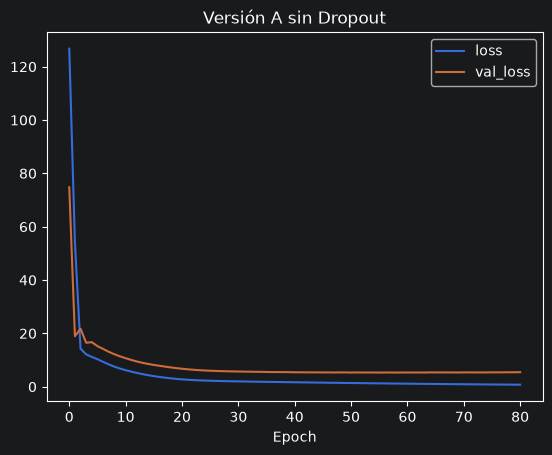

In [12]:
modelo_A.graficar_perdidas()

## 6.2 Versión A con Dropout

In [13]:
modelo_A_drop.entrenar(X_train_A, y_train);

Epoch 103: early stopping
Restoring model weights from the end of the best epoch: 78.


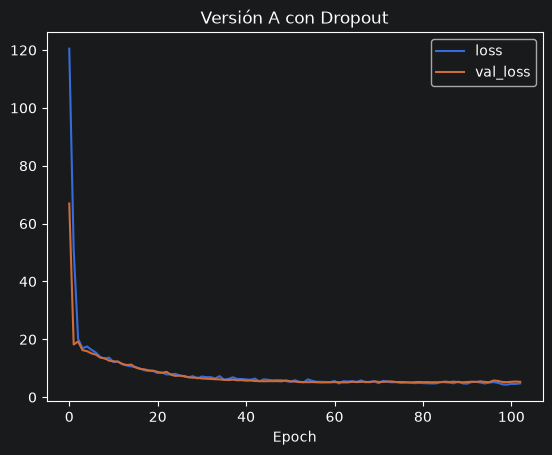

In [14]:
modelo_A_drop.graficar_perdidas()

## 6.3 Versión B sin Dropout

In [15]:
modelo_B.entrenar(X_train_B, y_train);

Epoch 62: early stopping
Restoring model weights from the end of the best epoch: 37.


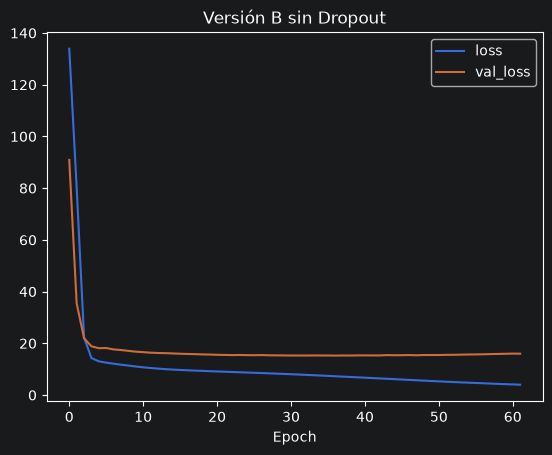

In [16]:
modelo_B.graficar_perdidas()

## 6.4 Versión B con Dropout

In [17]:
modelo_B_drop.entrenar(X_train_B, y_train);

Epoch 56: early stopping
Restoring model weights from the end of the best epoch: 31.


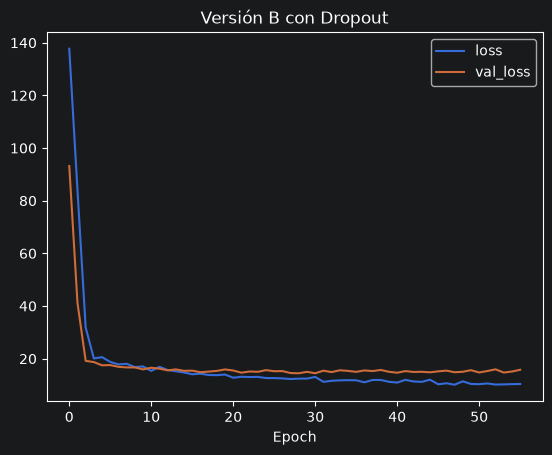

In [18]:
modelo_B_drop.graficar_perdidas()

# 7.Evaluación del modelo

In [19]:
#Cada objeto se evalúa con su método evaluar() (MAE, RMSE y varianza explicada)
resultados = pd.DataFrame([
    modelo_A.evaluar(X_test_A, y_test),
    modelo_A_drop.evaluar(X_test_A, y_test),
    modelo_B.evaluar(X_test_B, y_test),
    modelo_B_drop.evaluar(X_test_B, y_test)
])
resultados

,Modelo,MAE,RMSE,Varianza explicada
0,Versión A sin Dropout,1.161894,1.772559,0.823590
1,Versión A con Dropout,1.175927,1.684820,0.830683
2,Versión B sin Dropout,2.695730,3.702325,0.197078
3,Versión B con Dropout,2.655109,3.602048,0.207199


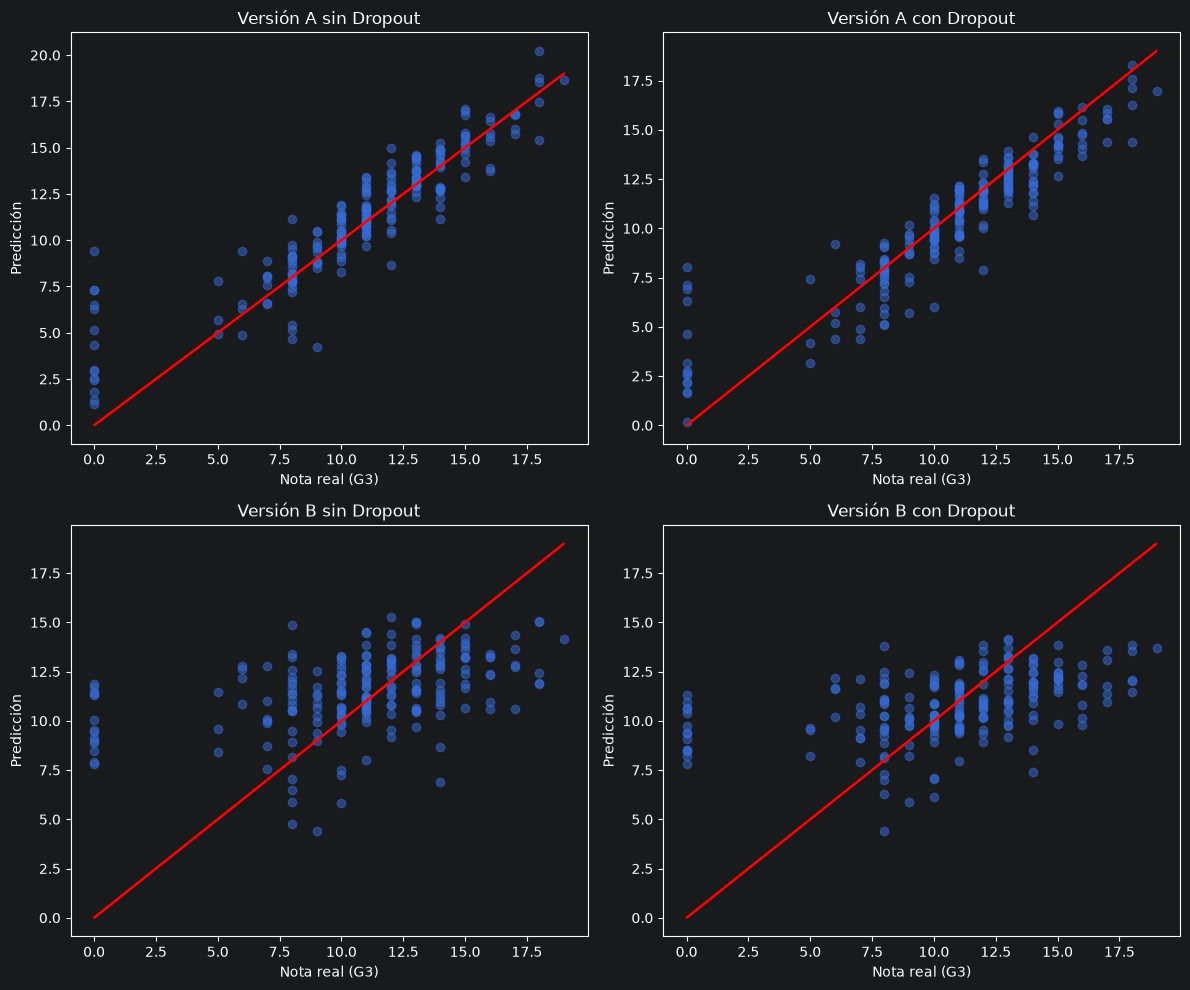

In [20]:
#Visualizar las predicciones: cuanto más cerca de la línea roja, mejor (la línea roja es la predicción perfecta)
modelos = [(modelo_A, X_test_A), (modelo_A_drop, X_test_A), (modelo_B, X_test_B), (modelo_B_drop, X_test_B)]

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, (modelo, X) in zip(axes.ravel(), modelos):
    ax.scatter(y_test, modelo.predecir(X), alpha=0.5)
    ax.plot(y_test, y_test, 'r') #predicción perfecta
    ax.set_title(modelo.nombre)
    ax.set_xlabel('Nota real (G3)')
    ax.set_ylabel('Predicción')
plt.tight_layout()
plt.show()

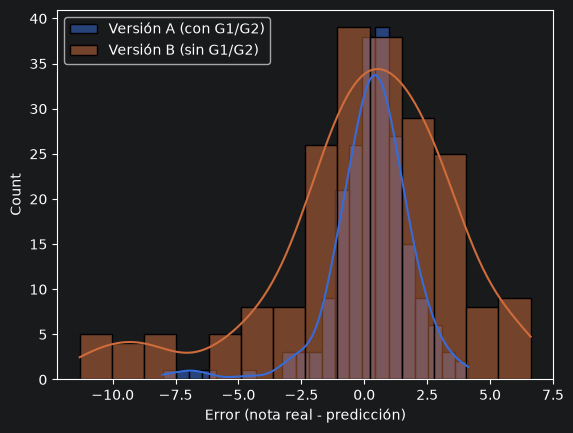

In [21]:
#Errores = nota real - predicción. Idealmente deben estar concentrados en 0
errores_A = y_test.values - modelo_A_drop.predecir(X_test_A)
errores_B = y_test.values - modelo_B_drop.predecir(X_test_B)

sns.histplot(errores_A, kde=True, label='Versión A (con G1/G2)')
sns.histplot(errores_B, kde=True, label='Versión B (sin G1/G2)')
plt.xlabel('Error (nota real - predicción)')
plt.legend()
plt.show()

# 8.Comparación y selección del mejor modelo

In [22]:
#¿En qué porcentaje nos estamos equivocando respecto a la nota promedio? (igual que el profe en el caso de viviendas)
resultados['MAE / promedio G3'] = resultados['MAE'] / train['G3'].mean()
resultados

,Modelo,MAE,RMSE,Varianza explicada,MAE / promedio G3
0,Versión A sin Dropout,1.161894,1.772559,0.823590,0.101124
1,Versión A con Dropout,1.175927,1.684820,0.830683,0.102345
2,Versión B sin Dropout,2.695730,3.702325,0.197078,0.234619
3,Versión B con Dropout,2.655109,3.602048,0.207199,0.231084


In [23]:
from sklearn.metrics import mean_absolute_error

#Referencia: si en vez de un modelo predijéramos siempre la nota promedio, ¿cuánto nos equivocaríamos?
prediccion_promedio = np.full(len(y_test), y_train.mean())
print('MAE prediciendo siempre el promedio:', mean_absolute_error(y_test, prediccion_promedio))

MAE prediciendo siempre el promedio: 2.9963899951293587


In [24]:
#Configuración extra de la Versión B: batch más grande (64) con Dropout, para intentar mejorarla
modelo_B_extra = ModeloRegresion(version='B', usar_dropout=True)
modelo_B_extra.nombre = 'Versión B con Dropout, batch 64'
modelo_B_extra.preparar_datos(train, test)
modelo_B_extra.entrenar(X_train_B, y_train, batch_size=64);

Epoch 78: early stopping
Restoring model weights from the end of the best epoch: 53.


In [25]:
fila_extra = modelo_B_extra.evaluar(X_test_B, y_test)
fila_extra['MAE / promedio G3'] = fila_extra['MAE'] / train['G3'].mean()
resultados = pd.concat([resultados, pd.DataFrame([fila_extra])], ignore_index=True)
resultados

,Modelo,MAE,RMSE,Varianza explicada,MAE / promedio G3
0,Versión A sin Dropout,1.161894,1.772559,0.823590,0.101124
1,Versión A con Dropout,1.175927,1.684820,0.830683,0.102345
2,Versión B sin Dropout,2.695730,3.702325,0.197078,0.234619
3,Versión B con Dropout,2.655109,3.602048,0.207199,0.231084
4,"Versión B con Dropout, batch 64",2.651716,3.623514,0.201031,0.230788


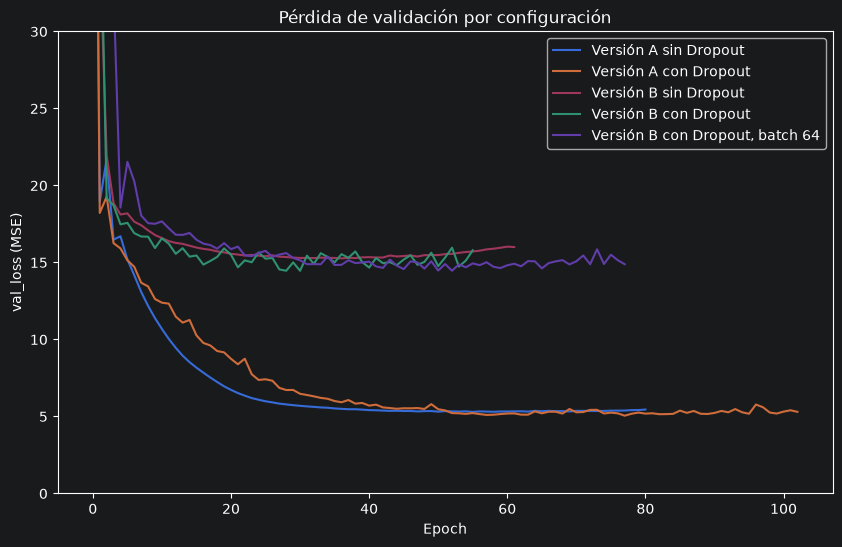

In [26]:
#Comparación de las curvas de validación (val_loss) de todas las configuraciones
plt.figure(figsize=(10,6))
for modelo in [modelo_A, modelo_A_drop, modelo_B, modelo_B_drop, modelo_B_extra]:
    plt.plot(modelo.historial['val_loss'], label=modelo.nombre)
plt.ylim(0, 30) #recortamos el eje para ver mejor las diferencias (al inicio las pérdidas son muy altas)
plt.xlabel('Epoch')
plt.ylabel('val_loss (MSE)')
plt.title('Pérdida de validación por configuración')
plt.legend()
plt.show()

**Comparación y selección del modelo**

- **Con notas parciales (Versión A)** el modelo predice la nota final con un error promedio de ~1.1 puntos (≈10 % de la nota promedio) y explica el 82 % de la variación de las notas.
- **Sin notas parciales (Versión B)** el error sube a ~2.7 puntos y solo se explica el ~20 % de la variación. Se probaron varias configuraciones (con y sin Dropout, batch 32 y 64) y todas dieron resultados similares; la mejor fue con Dropout y batch 64 (MAE 2.66). Como referencia, predecir siempre la nota promedio da un MAE de 3.0, por lo que el modelo sí aprende, pero la información disponible sin notas parciales es limitada.
- **El Dropout** redujo el overfitting (curvas de loss y val_loss más juntas), aunque casi no cambió el error final.
- **Ningún modelo detecta bien a los estudiantes con nota final 0** (posible abandono), que concentran los errores más grandes.

**Modelo seleccionado: Versión A con Dropout**, por tener el menor RMSE (1.70), la mayor varianza explicada (0.82) y menos overfitting. Como limitación, este

# 9.Guardar el modelo

In [27]:
#Guardamos el modelo seleccionado (Versión A con Dropout) con el método guardar()
modelo_A_drop.guardar('model1.keras')

In [28]:
from tensorflow.keras.models import load_model

#Cargar el modelo guardado en un objeto nuevo y comprobar que predice igual que el original
modelo_cargado = ModeloRegresion(version='A', usar_dropout=True)
modelo_cargado.modelo = load_model(config.RUTA_MODELS / 'model1.keras')
modelo_cargado.nombre = 'Modelo cargado'
modelo_cargado.evaluar(X_test_A, y_test)

{'Modelo': 'Modelo cargado',
 'MAE': 1.175926923751831,
 'RMSE': np.float64(1.684820166593205),
 'Varianza explicada': 0.8306825757026672}

**Nota para la API:** el modelo seleccionado usa las 62 variables de la Versión A, las mismas con las que se ajustó `models/scaler.pkl` en el preprocesamiento. Por eso la API puede usar ese mismo scaler y la lista `models/columnas.pkl` para preparar los datos de un estudiante nuevo antes de predecir con `models/model1.keras`.
